In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.metrics import r2_score


In [3]:
# ---- SET THESE ----

stationary_path = r"C:\Users\murat\Downloads\Stationary thermal nov 23 crop.JPG"
drone_path = r"C:\Users\murat\Downloads\Drone Thermal 23 Nov crop.JPG"# stationary ROI (right image)
# -------------------

# Read images (BGR)
drone_bgr = cv2.imread(drone_path)
stationary_bgr = cv2.imread(stationary_path)

assert drone_bgr is not None,  "Drone image not found"
assert stationary_bgr is not None, "Stationary image not found"

print("Drone shape:", drone_bgr.shape)
print("Stationary shape:", stationary_bgr.shape)


Drone shape: (148, 185, 3)
Stationary shape: (120, 150, 3)


In [4]:
# Convert to grayscale intensity (proxy for temperature)
drone_gray = cv2.cvtColor(drone_bgr, cv2.COLOR_BGR2GRAY)
stationary_gray_raw = cv2.cvtColor(stationary_bgr, cv2.COLOR_BGR2GRAY)

# Resize stationary ROI to drone ROI size so pixels roughly correspond
h, w = drone_gray.shape
stationary_gray = cv2.resize(
    stationary_gray_raw, (w, h), interpolation=cv2.INTER_AREA
)

# Light smoothing to suppress noise / pixel-level mismatch
drone_smooth = cv2.GaussianBlur(drone_gray, (5, 5), 0)
stationary_smooth = cv2.GaussianBlur(stationary_gray, (5, 5), 0)

print("Drone intensity range:", drone_smooth.min(), drone_smooth.max())
print("Stationary intensity range:", stationary_smooth.min(), stationary_smooth.max())


Drone intensity range: 111 178
Stationary intensity range: 177 221


In [5]:
# Flatten to 1D
x_all = drone_smooth.flatten().astype(np.float32)
y_all = stationary_smooth.flatten().astype(np.float32)

# Remove extreme tails (2nd–98th percentile) to drop obvious outliers
x_lo, x_hi = np.percentile(x_all, [2, 98])
y_lo, y_hi = np.percentile(y_all, [2, 98])

mask_basic = (x_all >= x_lo) & (x_all <= x_hi) & (y_all >= y_lo) & (y_all <= y_hi)

# Optional: define a "brick" threshold on drone intensity (warm pixels)
brick_threshold = np.percentile(x_all, 20)   # you can change this if you like
mask_brick = x_all >= brick_threshold

mask = mask_basic & mask_brick

x = x_all[mask]
y = y_all[mask]

print(f"Total pixels: {len(x_all)}, used as brick samples: {len(x)}")
print(f"Brick threshold on drone intensity: {brick_threshold:.2f}")


Total pixels: 27380, used as brick samples: 21967
Brick threshold on drone intensity: 124.00


In [10]:
# Prepare for sklearn
X = x.reshape(-1, 1)

poly_degree = 3  # quadratic; you can change to 1 or 3 if you want to test

base_model = make_pipeline(
    PolynomialFeatures(poly_degree, include_bias=False),
    LinearRegression()
)

ransac = RANSACRegressor(
    base_model,
    min_samples=0.8,
    residual_threshold=2.5,
    random_state=42
)

ransac.fit(X, y)

inlier_mask = ransac.inlier_mask_
inlier_ratio = inlier_mask.mean()

print(f"Inlier ratio: {inlier_ratio*100:.1f}%")

# R² on inliers
y_pred = ransac.predict(X)
r2 = r2_score(y[inlier_mask], y_pred[inlier_mask])
print(f"R² on inliers: {r2:.4f}")


Inlier ratio: 37.8%
R² on inliers: 0.9881


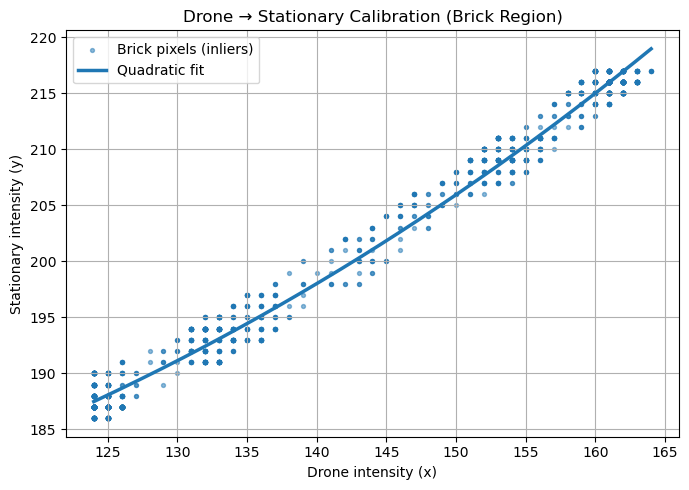

In [11]:
# For plotting, sample some inliers to avoid a huge scatter
rng = np.random.default_rng(0)
inlier_indices = np.where(inlier_mask)[0]
sample_size = min(2000, len(inlier_indices))
sample_idx = rng.choice(inlier_indices, size=sample_size, replace=False)

X_sample = X[sample_idx, 0]
y_sample = y[sample_idx]

# Build a smooth curve over the range
x_grid = np.linspace(X_sample.min(), X_sample.max(), 200).reshape(-1, 1)
y_grid = ransac.predict(x_grid)

plt.figure(figsize=(7, 5))
plt.scatter(X_sample, y_sample, s=8, alpha=0.5, label="Brick pixels (inliers)")
plt.plot(x_grid, y_grid, linewidth=2.5, label="Quadratic fit")

plt.xlabel("Drone intensity (x)")
plt.ylabel("Stationary intensity (y)")
plt.title("Drone → Stationary Calibration (Brick Region)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [14]:
# Extract the underlying LinearRegression from the RANSAC pipeline
estimator = ransac.estimator_
poly = estimator.named_steps["polynomialfeatures"]
lin = estimator.named_steps["linearregression"]

coefs = lin.coef_
intercept = float(lin.intercept_)

if poly_degree == 3:
    # PolynomialFeatures (deg=3, include_bias=False) --> [x, x^2, x^3]
    a1, a2, a3 = coefs
    A = float(a3)      # x^3
    B = float(a2)      # x^2
    C = float(a1)      # x
    D = float(intercept)

    print("Final model for brick pixels (x = drone intensity):")
    print(f"y = {A:.6f} * x**3 + {B:.6f} * x**2 + {C:.6f} * x + {D:.6f}")

elif poly_degree == 2:
    # keep this case in case you want to compare later
    a1, a2 = coefs    # [x, x^2]
    A = float(a2)
    B = float(a1)
    C = float(intercept)

    print("Final model for brick pixels (x = drone intensity):")
    print(f"y = {A:.6f} * x**2 + {B:.6f} * x + {C:.6f}")

else:
    print("Polynomial degree is not 2 or 3; inspect coefs directly:")
    print("coefs:", coefs)
    print("intercept:", intercept)


Final model for brick pixels (x = drone intensity):
y = 0.000013 * x**3 + 0.000000 * x**2 + 0.000000 * x + 163.528336


In [13]:
def calibrate_drone_intensity(drone_gray_img, ransac_model):
    """
    drone_gray_img: 2D uint8 or float array (grayscale)
    ransac_model: trained RANSACRegressor from above
    returns: calibrated stationary-like grayscale image (float32)
    """
    img = drone_gray_img.astype(np.float32)
    h, w = img.shape
    x_flat = img.reshape(-1, 1)
    y_flat = ransac_model.predict(x_flat)
    y_img = y_flat.reshape(h, w).astype(np.float32)
    return y_img

# Example: apply to the same drone ROI
calibrated_roi = calibrate_drone_intensity(drone_smooth, ransac)

print("Calibrated ROI stats (should be close to stationary_smooth):")
print("  mean stationary:", stationary_smooth.mean())
print("  mean calibrated:", calibrated_roi.mean())


Calibrated ROI stats (should be close to stationary_smooth):
  mean stationary: 200.19127100073047
  mean calibrated: 199.81888


=== Summary statistics ===
Stationary mean:   200.191
Calibrated mean:   199.819
Mean difference:   -0.372
Std of difference: 6.259


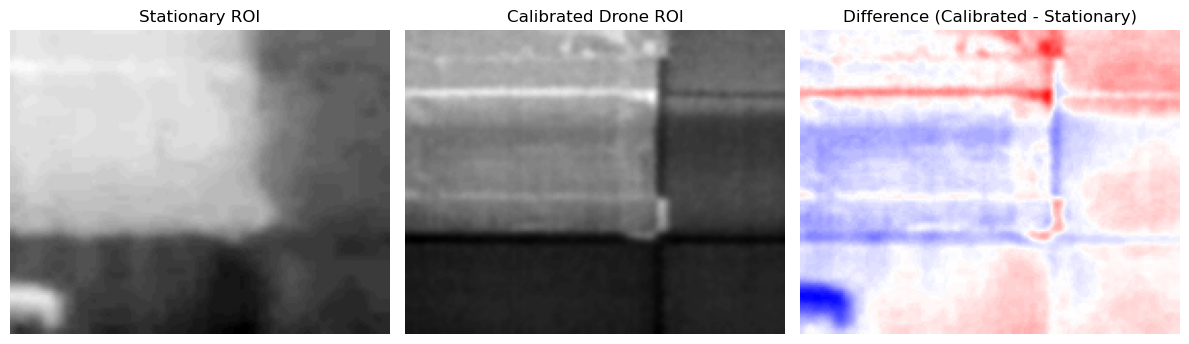

In [15]:
# Calibrate the drone ROI using the current RANSAC model
calibrated_roi = calibrate_drone_intensity(drone_smooth, ransac)

# Difference map: calibrated drone - stationary
diff = calibrated_roi - stationary_smooth.astype(np.float32)

print("=== Summary statistics ===")
print(f"Stationary mean:   {stationary_smooth.mean():.3f}")
print(f"Calibrated mean:   {calibrated_roi.mean():.3f}")
print(f"Mean difference:   {diff.mean():.3f}")
print(f"Std of difference: {diff.std():.3f}")

# Visual comparison: stationary vs calibrated vs difference
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(stationary_smooth, cmap="gray")
axes[0].set_title("Stationary ROI")
axes[0].axis("off")

axes[1].imshow(calibrated_roi, cmap="gray")
axes[1].set_title("Calibrated Drone ROI")
axes[1].axis("off")

vmax = np.max(np.abs(diff))
axes[2].imshow(diff, cmap="bwr", vmin=-vmax, vmax=vmax)
axes[2].set_title("Difference (Calibrated - Stationary)")
axes[2].axis("off")

plt.tight_layout()
plt.show()


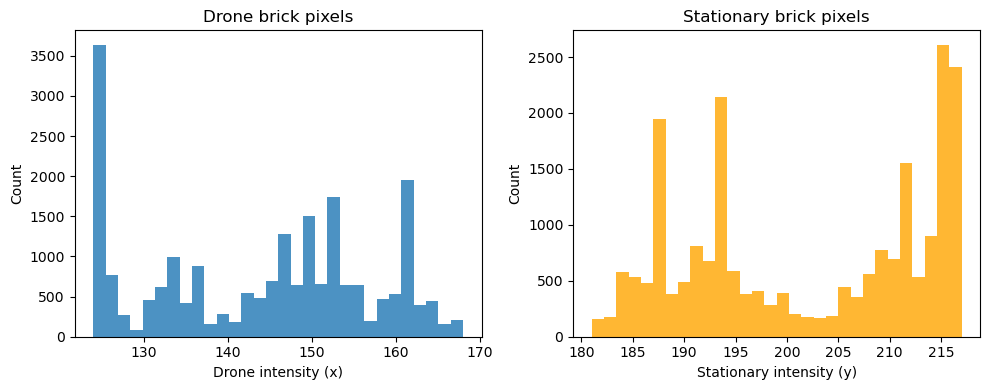

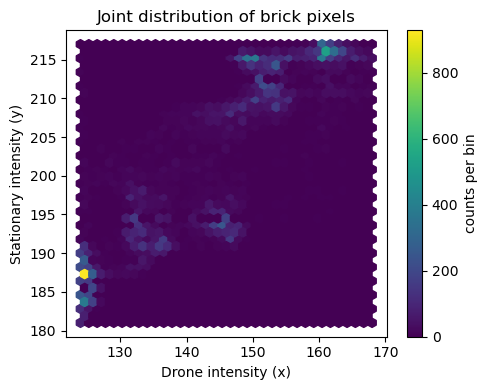

In [16]:
# ---- Distribution of brick-pixel intensities ----

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(x, bins=30, alpha=0.8)
plt.xlabel("Drone intensity (x)")
plt.ylabel("Count")
plt.title("Drone brick pixels")

plt.subplot(1, 2, 2)
plt.hist(y, bins=30, alpha=0.8, color="orange")
plt.xlabel("Stationary intensity (y)")
plt.ylabel("Count")
plt.title("Stationary brick pixels")

plt.tight_layout()
plt.show()

# ---- Joint distribution (hexbin) ----
plt.figure(figsize=(5, 4))
hb = plt.hexbin(x, y, gridsize=35, cmap="viridis")
plt.xlabel("Drone intensity (x)")
plt.ylabel("Stationary intensity (y)")
plt.title("Joint distribution of brick pixels")
plt.colorbar(hb, label="counts per bin")
plt.tight_layout()
plt.show()


Degree 1: R² = 0.78001
Degree 2: R² = 0.77584
Degree 3: R² = 0.76885


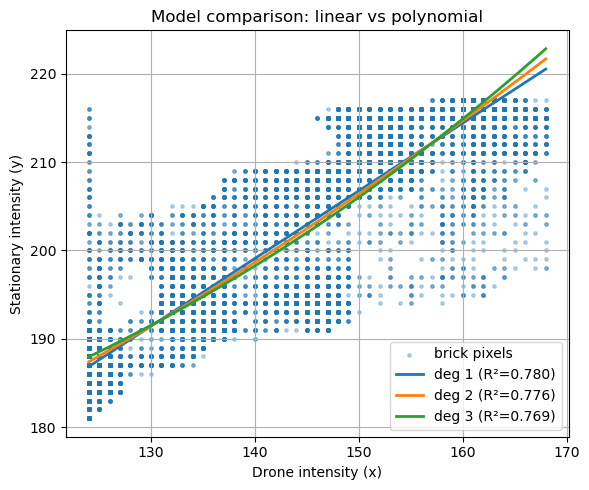

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

degrees = [1, 2, 3]
models_plain = {}
r2_scores = {}

X = x.reshape(-1, 1)

for d in degrees:
    pipe = make_pipeline(
        PolynomialFeatures(d, include_bias=False),
        LinearRegression()
    )
    pipe.fit(X, y)
    models_plain[d] = pipe
    y_pred = pipe.predict(X)
    r2 = r2_score(y, y_pred)
    r2_scores[d] = r2
    print(f"Degree {d}: R² = {r2:.5f}")

# Plot scatter + all three fits
x_grid = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)

plt.figure(figsize=(6, 5))
plt.scatter(x, y, s=6, alpha=0.3, label="brick pixels")

for d in degrees:
    y_grid = models_plain[d].predict(x_grid)
    plt.plot(x_grid, y_grid, linewidth=2,
             label=f"deg {d} (R²={r2_scores[d]:.3f})")

plt.xlabel("Drone intensity (x)")
plt.ylabel("Stationary intensity (y)")
plt.title("Model comparison: linear vs polynomial")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Residuals summary for degree 3:
  mean: -0.0023
  std:  5.5334
  min:  -24.8131
  max:  28.0498


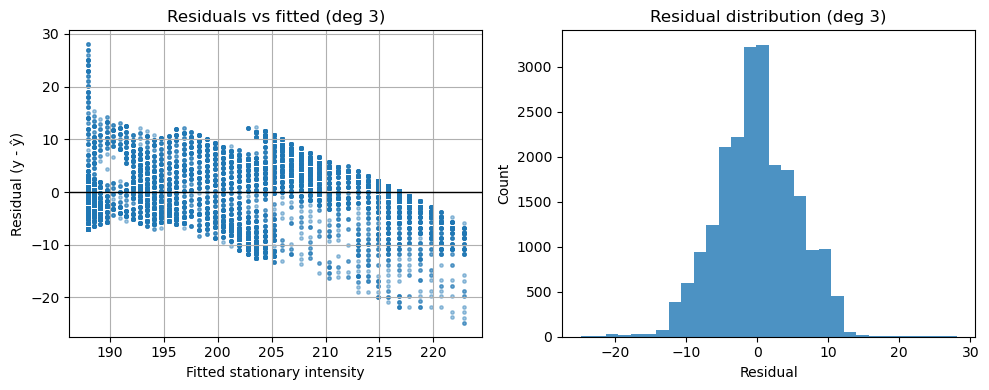

In [18]:
# Choose which degree you want to inspect
best_deg = 3      # change to 1 or 2 if you want
best_model = models_plain[best_deg]

y_pred_best = best_model.predict(X).ravel()
resid = y - y_pred_best

print(f"Residuals summary for degree {best_deg}:")
print(f"  mean: {resid.mean():.4f}")
print(f"  std:  {resid.std():.4f}")
print(f"  min:  {resid.min():.4f}")
print(f"  max:  {resid.max():.4f}")

plt.figure(figsize=(10, 4))

# Residuals vs fitted
plt.subplot(1, 2, 1)
plt.scatter(y_pred_best, resid, s=6, alpha=0.4)
plt.axhline(0, color="k", linewidth=1)
plt.xlabel("Fitted stationary intensity")
plt.ylabel("Residual (y - ŷ)")
plt.title(f"Residuals vs fitted (deg {best_deg})")
plt.grid(True)

# Residual histogram
plt.subplot(1, 2, 2)
plt.hist(resid, bins=30, alpha=0.8)
plt.xlabel("Residual")
plt.ylabel("Count")
plt.title(f"Residual distribution (deg {best_deg})")

plt.tight_layout()
plt.show()


Inliers plotted:  8313
Outliers plotted: 13654


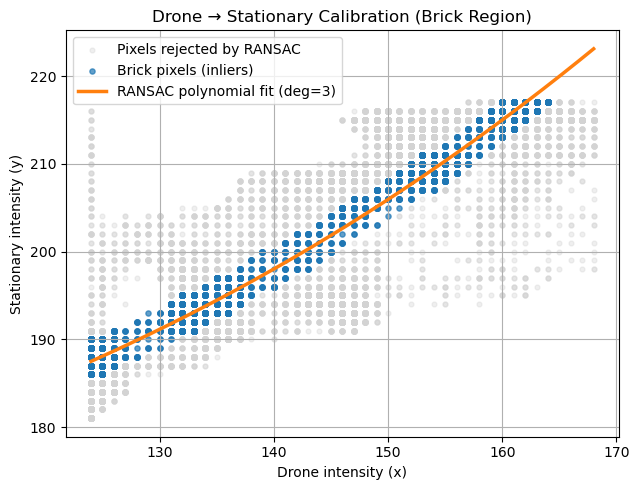

In [19]:
# New visualization: show inliers + outliers so it doesn't look unrealistically perfect

# Split data into inliers / outliers based on the existing RANSAC fit
x_in  = x[inlier_mask]
y_in  = y[inlier_mask]
x_out = x[~inlier_mask]
y_out = y[~inlier_mask]

print(f"Inliers plotted:  {len(x_in)}")
print(f"Outliers plotted: {len(x_out)}")

# Build x-grid and fitted curve from current RANSAC model
x_grid = np.linspace(x.min(), x.max(), 200).reshape(-1, 1)
y_grid = ransac.predict(x_grid)

plt.figure(figsize=(6.5, 5))

# Outliers: light gray, more scattered
plt.scatter(x_out, y_out, s=12, alpha=0.35, color="lightgray",
            label="Pixels rejected by RANSAC")

# Inliers: stronger color
plt.scatter(x_in, y_in, s=14, alpha=0.7, color="tab:blue",
            label="Brick pixels (inliers)")

# Fitted curve
plt.plot(x_grid, y_grid, linewidth=2.5, color="tab:orange",
         label=f"RANSAC polynomial fit (deg={poly_degree})")

plt.xlabel("Drone intensity (x)")
plt.ylabel("Stationary intensity (y)")
plt.title("Drone → Stationary Calibration (Brick Region)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
